In [2]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [4]:
# Load dataset
df = pd.read_csv('cpa.csv', sep='\t')

# Menampilkan 5 data pertama
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

In [5]:
# Melakukan eksplorasi awal
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

# Step 3: Identifikasi kolom numerik & kategori

In [6]:
# Identifikasi kolom numerik & kategori
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

print("Kolom numerik:", numeric_cols)
print("Kolom kategori:", categorical_cols)

Kolom numerik: Index(['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency',
       'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
       'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5',
       'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact',
       'Z_Revenue', 'Response'],
      dtype='object')
Kolom kategori: Index(['Education', 'Marital_Status', 'Dt_Customer'], dtype='object')


# Step 4: Imputasi missing value

In [7]:
# Imputasi missing value pada kolom Income
df['Income'] = df['Income'].fillna(df['Income'].median())

# Memeriksa missing value setelah imputasi
print("Missing value setelah imputasi:")
print(df.isnull().sum())
print("Missing value Income:", df['Income'].isnull().sum())

Missing value setelah imputasi:
ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64
Missing value Income: 0



# Step 5: Encoding fitur kategori

In [8]:
# Encoding fitur kategori
# Mengubah kolom tanggal menjadi fitur numerik
df['Dt_Customer'] = pd.to_datetime(
    df['Dt_Customer'],
    format='%d-%m-%Y'
)

df['Customer_Tenure'] = (
    df['Dt_Customer'].max() - df['Dt_Customer']
).dt.days

df = df.drop(columns=['Dt_Customer'])

# Melakukan One-Hot Encoding
categorical_cols = ['Education', 'Marital_Status']

encoder = OneHotEncoder(handle_unknown='ignore')

encoded_data = encoder.fit_transform(df[categorical_cols])

encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df.index
)

display(encoded_df.head())

,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


#Gabungkan data numerik & hasil encoding

In [9]:
# Menyiapkan fitur numerik
drop_cols = ['ID', 'Z_CostContact', 'Z_Revenue']

numeric_features = [
    col for col in numeric_cols
    if col not in drop_cols
]

numeric_features.append('Customer_Tenure')
numeric_df = df[numeric_features].copy()

#Menampilkan fitur numerik
display(numeric_df.head())

# Menggabungkan data numerik dan hasil encoding
df_processed = pd.concat(
    [numeric_df, encoded_df],
    axis=1
)

# Menampilkan hasil penggabungan
display(df_processed.head())

# Memeriksa hasil penggabungan
# Memeriksa ukuran dataset setelah encoding
print("Ukuran data sebelum encoding:", df.shape)
print("Ukuran data setelah encoding:", df_processed.shape)

# Memeriksa missing value
print("\nMissing value:")
print(df_processed.isnull().sum().sum())

# Memeriksa tipe data
print("\nTipe data:")
print(df_processed.dtypes.value_counts())

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Customer_Tenure
0,1957,58138.0,0,0,58,635,88,546,172,88,...,4,7,0,0,0,0,0,0,1,663
1,1954,46344.0,1,1,38,11,1,6,2,1,...,2,5,0,0,0,0,0,0,0,113
2,1965,71613.0,0,0,26,426,49,127,111,21,...,10,4,0,0,0,0,0,0,0,312
3,1984,26646.0,1,0,26,11,4,20,10,3,...,4,6,0,0,0,0,0,0,0,139
4,1981,58293.0,1,0,94,173,43,118,46,27,...,6,5,0,0,0,0,0,0,0,161


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,1957,58138.0,0,0,58,635,88,546,172,88,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1954,46344.0,1,1,38,11,1,6,2,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1965,71613.0,0,0,26,426,49,127,111,21,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1984,26646.0,1,0,26,11,4,20,10,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1981,58293.0,1,0,94,173,43,118,46,27,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Ukuran data sebelum encoding: (2240, 29)
Ukuran data setelah encoding: (2240, 37)

Missing value:
0

Tipe data:
int64      23
float64    14
Name: count, dtype: int64


# Step 6: Scaling data

In [10]:
# Scaling data
# Membuat objek StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_processed)

# Mengubah hasil scaling menjadi DataFrame
df_scaled = pd.DataFrame(
    X_scaled,
    columns=df_processed.columns,
    index=df_processed.index
)

# Menampilkan 5 data pertama
display(df_scaled.head())

# Memeriksa rata-rata setiap fitur
print("\nRata-rata setiap fitur:")
print(df_scaled.mean().round(2))

# Memeriksa standar deviasi setiap fitur
print("\nStandar deviasi setiap fitur:")
print(df_scaled.std().round(2))

# Membandingkan data sebelum dan sesudah scaling
print("Data sebelum scaling:")
display(df_processed[['Income', 'MntWines', 'Recency']].head())

print("Data setelah scaling:")
display(df_scaled[['Income', 'MntWines', 'Recency']].head())

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,-0.985345,0.235696,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,1.476500,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
1,-1.235733,-0.235454,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,-0.631503,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
2,-0.317643,0.773999,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,-0.146905,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
3,1.268149,-1.022355,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,-0.583043,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
4,1.017761,0.241888,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,-0.001525,...,-0.444816,1.899751,-0.029894,-0.036621,-0.339909,1.261980,-0.522233,-0.591099,-0.188676,-0.029894



Rata-rata setiap fitur:
Year_Birth                -0.0
Income                    -0.0
Kidhome                   -0.0
Teenhome                  -0.0
Recency                   -0.0
MntWines                  -0.0
MntFruits                 -0.0
MntMeatProducts            0.0
MntFishProducts            0.0
MntSweetProducts          -0.0
MntGoldProds              -0.0
NumDealsPurchases         -0.0
NumWebPurchases           -0.0
NumCatalogPurchases        0.0
NumStorePurchases          0.0
NumWebVisitsMonth         -0.0
AcceptedCmp3              -0.0
AcceptedCmp4               0.0
AcceptedCmp5              -0.0
AcceptedCmp1               0.0
AcceptedCmp2               0.0
Complain                  -0.0
Response                  -0.0
Customer_Tenure            0.0
Education_2n Cycle         0.0
Education_Basic           -0.0
Education_Graduation      -0.0
Education_Master           0.0
Education_PhD             -0.0
Marital_Status_Absurd      0.0
Marital_Status_Alone      -0.0
Marital_Status

,Income,MntWines,Recency
0,58138.0,635,58
1,46344.0,11,38
2,71613.0,426,26
3,26646.0,11,26
4,58293.0,173,94


Data setelah scaling:


,Income,MntWines,Recency
0,0.235696,0.983781,0.307039
1,-0.235454,-0.870479,-0.383664
2,0.773999,0.362723,-0.798086
3,-1.022355,-0.870479,-0.798086
4,0.241888,-0.389085,1.550305



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

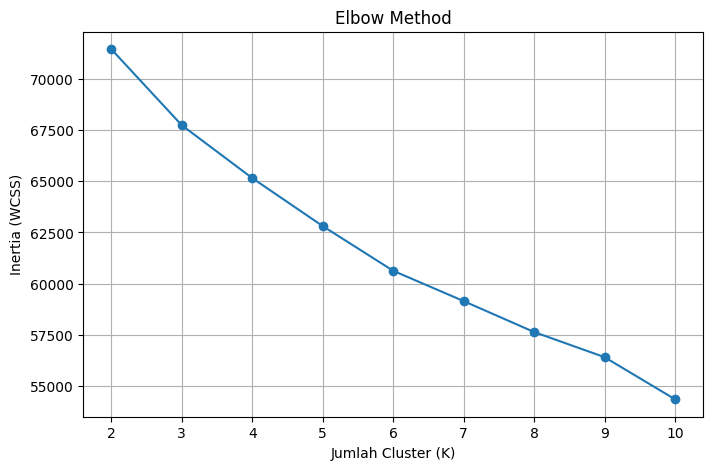

K = 2, Silhouette Score = 0.1723
K = 3, Silhouette Score = 0.1082
K = 4, Silhouette Score = 0.1087
K = 5, Silhouette Score = 0.1236
K = 6, Silhouette Score = 0.1246
K = 7, Silhouette Score = 0.0895
K = 8, Silhouette Score = 0.0981
K = 9, Silhouette Score = 0.0762
K = 10, Silhouette Score = 0.0822


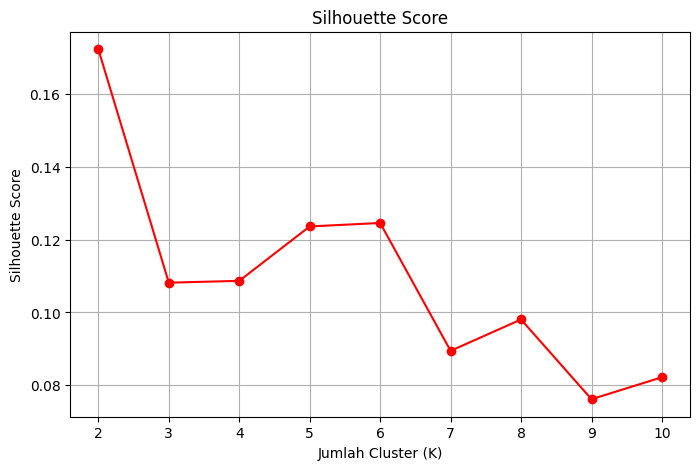

Jumlah cluster terbaik: 2
Silhouette Score terbaik: 0.17227817680207946


In [11]:
# Menentukan nilai K menggunakan Elbow Method
# Menentukan nilai K yang akan diuji
k_values = range(2, 11)

# Menyimpan nilai inertia
inertia = []

# Melatih K-Means untuk setiap nilai K
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Membuat grafik Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o')

plt.title('Elbow Method')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(k_values)
plt.grid(True)

plt.show()

# Menentukan nilai K menggunakan Silhouette Score
# Menyimpan nilai Silhouette Score
silhouette_scores = []

# Menghitung Silhouette Score untuk setiap K
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Membuat grafik Silhouette Score
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker='o',
    color='red'
)

plt.title('Silhouette Score')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.xticks(k_values)
plt.grid(True)

plt.show()

# Menentukan K dengan Silhouette Score tertinggi
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Jumlah cluster terbaik:", best_k)
print("Silhouette Score terbaik:", max(silhouette_scores))

# Step 8: Pilih k optimal dan klasterisasi

In [12]:
# Menentukan jumlah cluster optimal
optimal_k = 2

# Membuat model K-Means
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Melakukan clustering
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Menampilkan hasil clustering
display(df[['Cluster']].head())

# Menghitung jumlah pelanggan setiap cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

print("Jumlah pelanggan setiap cluster:")
print(cluster_counts)

# Menghitung persentase pelanggan setiap cluster
cluster_percentage = (
    df['Cluster'].value_counts(normalize=True).sort_index() * 100
)

print("Persentase pelanggan setiap cluster:")
print(cluster_percentage.round(2))

# Menampilkan data pelanggan dan hasil cluster
display(df.head(10))

,Cluster
0,1
1,0
2,1
3,0
4,0


Jumlah pelanggan setiap cluster:
Cluster
0    1356
1     884
Name: count, dtype: int64
Persentase pelanggan setiap cluster:
Cluster
0    60.54
1    39.46
Name: proportion, dtype: float64


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Customer_Tenure,Cluster
0,5524,1957,Graduation,Single,58138.0,0,0,58,635,88,...,0,0,0,0,0,3,11,1,663,1
1,2174,1954,Graduation,Single,46344.0,1,1,38,11,1,...,0,0,0,0,0,3,11,0,113,0
2,4141,1965,Graduation,Together,71613.0,0,0,26,426,49,...,0,0,0,0,0,3,11,0,312,1
3,6182,1984,Graduation,Together,26646.0,1,0,26,11,4,...,0,0,0,0,0,3,11,0,139,0
4,5324,1981,PhD,Married,58293.0,1,0,94,173,43,...,0,0,0,0,0,3,11,0,161,0
5,7446,1967,Master,Together,62513.0,0,1,16,520,42,...,0,0,0,0,0,3,11,0,293,1
6,965,1971,Graduation,Divorced,55635.0,0,1,34,235,65,...,0,0,0,0,0,3,11,0,593,1
7,6177,1985,PhD,Married,33454.0,1,0,32,76,10,...,0,0,0,0,0,3,11,0,417,0
8,4855,1974,PhD,Together,30351.0,1,0,19,14,0,...,0,0,0,0,0,3,11,1,388,0
9,5899,1950,PhD,Together,5648.0,1,1,68,28,0,...,0,0,0,0,0,3,11,0,108,0


# Step 9: Visualisasi klaster dengan PCA 2D

,PC1,PC2,Cluster
0,3.858040,-0.547440,1
1,-2.371386,-0.614038,0
2,1.644802,-0.416982,1
3,-2.506401,-1.598636,0
4,-0.501727,0.165687,0


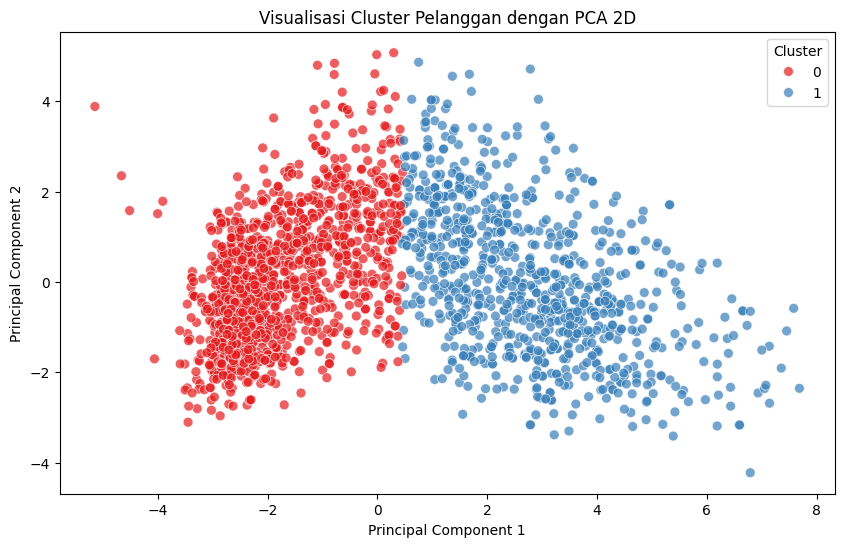

Variansi PC1: 17.73 %
Variansi PC2: 6.03 %
Total variansi: 23.76 %


In [13]:
# Melakukan reduksi dimensi menggunakan PCA
# Membuat objek PCA dengan 2 komponen
pca = PCA(n_components=2)

# Melakukan reduksi dimensi
X_pca = pca.fit_transform(X_scaled)

# Membuat DataFrame hasil PCA
df_pca = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Menambahkan label cluster
df_pca['Cluster'] = df['Cluster']

# Menampilkan hasil PCA
display(df_pca.head())

# Visualisasi hasil clustering menggunakan PCA
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set1',
    s=50,
    alpha=0.7
)

plt.title('Visualisasi Cluster Pelanggan dengan PCA 2D')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')

plt.show()

# Menghitung explained variance
explained_variance = pca.explained_variance_ratio_

print("Variansi PC1:", round(explained_variance[0] * 100, 2), "%")
print("Variansi PC2:", round(explained_variance[1] * 100, 2), "%")

print(
    "Total variansi:",
    round(sum(explained_variance) * 100, 2),
    "%"
)

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [14]:
# Menghitung rata-rata fitur berdasarkan cluster
cluster_profile = df.groupby('Cluster')[numeric_features].mean()

# Membulatkan hasil menjadi 2 angka desimal
cluster_profile = cluster_profile.round(2)

# Menampilkan profil cluster
display(cluster_profile)

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Customer_Tenure
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1969.93,39263.75,0.69,0.56,48.82,106.47,6.66,38.06,9.86,6.83,...,3.98,6.39,0.07,0.04,0.00,0.01,0.00,0.01,0.09,338.48
1,1967.08,72139.62,0.07,0.42,49.56,606.83,56.43,364.65,79.97,58.09,...,8.56,3.67,0.08,0.13,0.18,0.15,0.03,0.01,0.23,376.75


# Simpulkan Analisa dari hasil
Berdasarkan hasil analisis menggunakan metode K-Means Clustering pada dataset Customer Personality Analysis yang terdiri dari 2.240 data pelanggan, diperoleh dua kelompok pelanggan, yaitu Cluster 0 dan Cluster 1. Pengelompokan dilakukan berdasarkan karakteristik demografis, pendapatan, serta perilaku pembelian pelanggan.

1. Cluster 0

   Cluster ini terdiri dari 1.356 pelanggan atau sekitar 60,54% dari keseluruhan data. Kelompok ini memiliki rata-rata pendapatan dan pengeluaran yang lebih rendah dibandingkan Cluster 1. Frekuensi pembelian di toko juga relatif lebih sedikit, sedangkan jumlah kunjungan ke situs web lebih tinggi. Tingkat respons terhadap kampanye pemasaran berada di sekitar 9%.

2. Cluster 1

   Cluster ini terdiri dari 884 pelanggan atau sekitar 39,46% dari keseluruhan data. Kelompok ini memiliki rata-rata pendapatan dan pengeluaran yang jauh lebih tinggi. Pelanggan pada kelompok ini juga melakukan lebih banyak pembelian di toko dan memiliki jumlah kunjungan situs web yang lebih rendah. Tingkat respons terhadap kampanye pemasaran mencapai sekitar 23%, lebih tinggi dibandingkan Cluster 0.

Berdasarkan hasil tersebut, perusahaan dapat menerapkan strategi pemasaran yang berbeda untuk setiap kelompok pelanggan. Cluster 0 dapat menjadi sasaran promosi berupa diskon, paket hemat, atau penawaran khusus untuk mendorong pembelian. Sementara itu, Cluster 1 dapat diberikan program loyalitas, penawaran eksklusif, serta promosi produk premium untuk mempertahankan loyalitas dan meningkatkan nilai pembelian.